In [ ]:
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries loaded.")

Libraries loaded.


In [ ]:
from google.colab import files
import io

# Load the dataset
uploaded = files.upload()

# Find the uploaded file key (handles cases when name is changed to 'ObesityDataSet (1).csv' etc.)
file_key = next((k for k in uploaded.keys() if "ObesityDataSet" in k), "ObesityDataSet.csv")
df = pd.read_csv(io.BytesIO(uploaded[file_key]))

# Display the first five observations
display(df.head())

# Dataset dimensions
print(f"Dataset shape: {df.shape}")
print("Number of observations:", df.shape[0])
print("Number of variables:", df.shape[1])

# Variable names and data types
print("\nVariable information:")
df.info()

Saving ObesityDataSet.csv to ObesityDataSet (2).csv


,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
0,Female,21.0,1.62,64.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation,Normal_Weight
1,Female,21.0,1.52,56.0,yes,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,Male,23.0,1.80,77.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation,Normal_Weight
3,Male,27.0,1.80,87.0,no,no,3.0,3.0,Sometimes,no,2.0,no,2.0,0.0,Frequently,Walking,Overweight_Level_I
4,Male,22.0,1.78,89.8,no,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II


Dataset shape: (2111, 17)
Number of observations: 2111
Number of variables: 17

Variable information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2111 entries, 0 to 2110
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Gender                          2111 non-null   object 
 1   Age                             2111 non-null   float64
 2   Height                          2111 non-null   float64
 3   Weight                          2111 non-null   float64
 4   family_history_with_overweight  2111 non-null   object 
 5   FAVC                            2111 non-null   object 
 6   FCVC                            2111 non-null   float64
 7   NCP                             2111 non-null   float64
 8   CAEC                            2111 non-null   object 
 9   SMOKE                           2111 non-null   object 
 10  CH2O                            2111 non-null   float6

In [ ]:
missing_values = pd.DataFrame({
    "Missing values": df.isna().sum(),
    "Missing percentage (%)": df.isna().mean() * 100
})

display(missing_values)

,Missing values,Missing percentage (%)
Gender,0,0.0
Age,0,0.0
Height,0,0.0
Weight,0,0.0
family_history_with_overweight,0,0.0
FAVC,0,0.0
FCVC,0,0.0
NCP,0,0.0
CAEC,0,0.0
SMOKE,0,0.0


In [ ]:

duplicate_rows_count = df.duplicated().sum()
print(f"Duplicates found: {duplicate_rows_count}")

if duplicate_rows_count > 0:

    df = df.drop_duplicates(keep='first')
    print(f"Duplicates deleted succsesfully. New sample dimentions: {df.shape}")
else:
    print("No duplicates found.")

Duplicates found: 24
Duplicates deleted succsesfully. New sample dimentions: (2087, 17)


In [ ]:

numeric_columns = [
    "Age",
    "Height",
    "Weight",
    "FCVC",
    "NCP",
    "CH2O",
    "FAF",
    "TUE"
]

# Basic descriptive statistics
numeric_statistics = df[numeric_columns].describe().T

display(numeric_statistics)

,count,mean,std,min,25%,50%,75%,max
Age,2087.0,24.353090,6.368801,14.00,19.915937,22.847618,26.000000,61.00
Height,2087.0,1.702674,0.093186,1.45,1.630178,1.701584,1.769491,1.98
Weight,2087.0,86.858730,26.190847,39.00,66.000000,83.101100,108.015907,173.00
FCVC,2087.0,2.421466,0.534737,1.00,2.000000,2.396265,3.000000,3.00
NCP,2087.0,2.701179,0.764614,1.00,2.697467,3.000000,3.000000,4.00
CH2O,2087.0,2.004749,0.608284,1.00,1.590922,2.000000,2.466193,3.00
FAF,2087.0,1.012812,0.853475,0.00,0.124505,1.000000,1.678102,3.00
TUE,2087.0,0.663035,0.608153,0.00,0.000000,0.630866,1.000000,2.00


In [ ]:
descriptive_statistics = []

for column in numeric_columns:

    data = pd.to_numeric(df[column], errors="coerce").dropna()

    # Mode
    mode_values = data.mode()

    # If there is more than one mode, display all modes
    if len(mode_values) == 1:
        mode = mode_values.iloc[0]
    else:
        mode = ", ".join(
            [f"{value:.4f}" for value in mode_values]
        )

    # Quartiles
    q1 = data.quantile(0.25)
    median = data.quantile(0.50)
    q3 = data.quantile(0.75)

    # Minimum and maximum
    minimum = data.min()
    maximum = data.max()

    # Range and interquartile range
    data_range = maximum - minimum
    iqr = q3 - q1

    # Add results
    descriptive_statistics.append({
        "Variable": column,
        "Mean": data.mean(),
        "Median": median,
        "Mode": mode,
        "Minimum": minimum,
        "Q1 (25%)": q1,
        "Q2 (50%)": median,
        "Q3 (75%)": q3,
        "Maximum": maximum,
        "Range": data_range,
        "Interquartile Range (IQR)": iqr,
        "Variance": data.var(),
        "Standard Deviation": data.std(),
        "Skewness": data.skew(),
        "Kurtosis": data.kurt()
    })

# Create the summary table
descriptive_statistics = pd.DataFrame(descriptive_statistics)

# Display the results
display(descriptive_statistics)

,Variable,Mean,Median,Mode,Minimum,Q1 (25%),Q2 (50%),Q3 (75%),Maximum,Range,Interquartile Range (IQR),Variance,Standard Deviation,Skewness,Kurtosis
0,Age,24.353090,22.847618,18.0,14.00,19.915937,22.847618,26.000000,61.00,47.00,6.084063,40.561632,6.368801,1.514305,2.767690
1,Height,1.702674,1.701584,1.7,1.45,1.630178,1.701584,1.769491,1.98,0.53,0.139313,0.008684,0.093186,-0.024743,-0.555823
2,Weight,86.858730,83.101100,80.0,39.00,66.000000,83.101100,108.015907,173.00,134.00,42.015907,685.960471,26.190847,0.241902,-0.705478
3,FCVC,2.421466,2.396265,3.0,1.00,2.000000,2.396265,3.000000,3.00,2.00,1.000000,0.285943,0.534737,-0.448201,-0.623538
4,NCP,2.701179,3.000000,3.0,1.00,2.697467,3.000000,3.000000,4.00,3.00,0.302533,0.584635,0.764614,-1.138264,0.534931
5,CH2O,2.004749,2.000000,2.0,1.00,1.590922,2.000000,2.466193,3.00,2.00,0.875271,0.370010,0.608284,-0.106330,-0.863612
6,FAF,1.012812,1.000000,0.0,0.00,0.124505,1.000000,1.678102,3.00,3.00,1.553597,0.728419,0.853475,0.494320,-0.637961
7,TUE,0.663035,0.630866,0.0,0.00,0.000000,0.630866,1.000000,2.00,2.00,1.000000,0.369850,0.608153,0.609225,-0.553611


In [ ]:
categorical_columns = [
    "Gender",
    "family_history_with_overweight",
    "FAVC",
    "CAEC",
    "SMOKE",
    "SCC",
    "CALC",
    "MTRANS",
    "NObeyesdad"
]

for column in categorical_columns:

    print("\n" + "=" * 60)
    print(f"{column}")
    print("=" * 60)

    frequency_table = df[column].value_counts(dropna=False).to_frame(
        name="Frequency"
    )

    frequency_table["Percentage (%)"] = (
        frequency_table["Frequency"] / len(df) * 100
    )

    display(frequency_table)


Gender


,Frequency,Percentage (%)
Gender,,
Male,1052,50.407283
Female,1035,49.592717



family_history_with_overweight


,Frequency,Percentage (%)
family_history_with_overweight,,
yes,1722,82.510781
no,365,17.489219



FAVC


...

,Frequency,Percentage (%)
CALC,,
Sometimes,1380,66.123622
no,636,30.474365
Frequently,70,3.354097
Always,1,0.047916



MTRANS


,Frequency,Percentage (%)
MTRANS,,
Public_Transportation,1558,74.652611
Automobile,456,21.849545
Walking,55,2.635362
Motorbike,11,0.527072
Bike,7,0.335410



NObeyesdad


,Frequency,Percentage (%)
NObeyesdad,,
Obesity_Type_I,351,16.818400
Obesity_Type_III,324,15.524677
Obesity_Type_II,297,14.230954
Overweight_Level_II,290,13.895544
Normal_Weight,282,13.512218
Overweight_Level_I,276,13.224724
Insufficient_Weight,267,12.793483


In [ ]:
crosstab_pairs = [
    ("Gender", "NObeyesdad"),
    ("family_history_with_overweight", "NObeyesdad"),
    ("FAVC", "NObeyesdad")
]

for row_variable, column_variable in crosstab_pairs:

    print("\n" + "=" * 70)
    print(
        f"Crosstab (frequencies): {row_variable} × {column_variable}"
    )
    print("=" * 70)

    crosstab = pd.crosstab(
        df[row_variable],
        df[column_variable]
    )

    display(crosstab)

    print("\n" + "=" * 70)
    print(
        f"Crosstab (total percentages): {row_variable} × {column_variable}"
    )
    print("=" * 70)

    crosstab_total_percent = pd.crosstab(
        df[row_variable],
        df[column_variable],
        normalize="all"
    ) * 100

    display(crosstab_total_percent.round(2))


Crosstab (frequencies): Gender × NObeyesdad


NObeyesdad,Insufficient_Weight,Normal_Weight,Obesity_Type_I,Obesity_Type_II,Obesity_Type_III,Overweight_Level_I,Overweight_Level_II
Gender,,,,,,,
Female,169,137,156,2,323,145,103
Male,98,145,195,295,1,131,187



Crosstab (total percentages): Gender × NObeyesdad


NObeyesdad,Insufficient_Weight,Normal_Weight,Obesity_Type_I,Obesity_Type_II,Obesity_Type_III,Overweight_Level_I,Overweight_Level_II
Gender,,,,,,,
Female,8.1,6.56,7.47,0.10,15.48,6.95,4.94
Male,4.7,6.95,9.34,14.14,0.05,6.28,8.96



Crosstab (frequencies): family_history_with_overweight × NObeyesdad


...

NObeyesdad,Insufficient_Weight,Normal_Weight,Obesity_Type_I,Obesity_Type_II,Obesity_Type_III,Overweight_Level_I,Overweight_Level_II
family_history_with_overweight,,,,,,,
no,6.80,6.23,0.34,0.05,0.00,3.21,0.86
yes,5.99,7.28,16.48,14.18,15.52,10.01,13.03



Crosstab (frequencies): FAVC × NObeyesdad


NObeyesdad,Insufficient_Weight,Normal_Weight,Obesity_Type_I,Obesity_Type_II,Obesity_Type_III,Overweight_Level_I,Overweight_Level_II
FAVC,,,,,,,
no,50,78,11,7,1,22,74
yes,217,204,340,290,323,254,216



Crosstab (total percentages): FAVC × NObeyesdad


NObeyesdad,Insufficient_Weight,Normal_Weight,Obesity_Type_I,Obesity_Type_II,Obesity_Type_III,Overweight_Level_I,Overweight_Level_II
FAVC,,,,,,,
no,2.4,3.74,0.53,0.34,0.05,1.05,3.55
yes,10.4,9.77,16.29,13.90,15.48,12.17,10.35


In [ ]:
# Calculate z-scores for all numerical variables

z_scores = pd.DataFrame(
    stats.zscore(
        df[numeric_columns],
        nan_policy="omit"
    ),
    columns=numeric_columns,
    index=df.index
)

print("z-scores for the numerical variables:")
display(z_scores.head())


# z-scores summary

z_score_summary = pd.DataFrame({
    "Variable": numeric_columns,
    "Mean of z-scores": [
        z_scores[column].mean()
        for column in numeric_columns
    ],
    "Std of z-scores": [
        z_scores[column].std()
        for column in numeric_columns
    ],
    "Minimum z-score": [
        z_scores[column].min()
        for column in numeric_columns
    ],
    "Maximum z-score": [
        z_scores[column].max()
        for column in numeric_columns
    ]
})

display(z_score_summary.round(4))

z-scores for the numerical variables:


,Age,Height,Weight,FCVC,NCP,CH2O,FAF,TUE
0,-0.526613,-0.887408,-0.872985,-0.788364,0.390906,-0.007810,-1.186977,0.554211
1,-0.526613,-1.960788,-1.178508,1.082164,0.390906,1.636552,2.328908,-1.090505
2,-0.212507,1.044677,-0.376509,-0.788364,0.390906,-0.007810,1.156947,0.554211
3,0.415705,1.044677,0.005395,1.082164,0.390906,-0.007810,1.156947,-1.090505
4,-0.369560,0.830001,0.112328,-0.788364,-2.225418,-0.007810,-1.186977,-1.090505


,Variable,Mean of z-scores,Std of z-scores,Minimum z-score,Maximum z-score
0,Age,-0.0,1.0002,-1.6260,5.7555
1,Height,0.0,1.0002,-2.7122,2.9768
2,Weight,-0.0,1.0002,-1.8277,3.2898
3,FCVC,-0.0,1.0002,-2.6589,1.0822
4,NCP,0.0,1.0002,-2.2254,1.6991
5,CH2O,0.0,1.0002,-1.6522,1.6366
6,FAF,0.0,1.0002,-1.1870,2.3289
7,TUE,-0.0,1.0002,-1.0905,2.1989


In [ ]:
Z_THRESHOLD = 3

z_outlier_flags = pd.DataFrame(
    False,
    index=df.index,
    columns=numeric_columns
)

for column in numeric_columns:
    z_outlier_flags[column] = z_scores[column].abs() > Z_THRESHOLD

# Number of potential outliers for each variable
z_outlier_summary = pd.DataFrame({
    "Variable": numeric_columns,
    "Potential outliers": [
        z_outlier_flags[column].sum()
        for column in numeric_columns
    ]
})

z_outlier_summary["Percentage (%)"] = (
    z_outlier_summary["Potential outliers"]
    / len(df) * 100
)

display(z_outlier_summary.round(2))


# z-score outlier observations

for column in numeric_columns:

    outlier_indices = z_outlier_flags.index[
        z_outlier_flags[column]
    ]

    if len(outlier_indices) > 0:

        print("\n" + "=" * 70)
        print(f"z-score outliers: {column}")
        print("=" * 70)

        outlier_table = df.loc[
            outlier_indices,
            [column]
        ].copy()

        outlier_table["z-score"] = z_scores.loc[
            outlier_indices,
            column
        ]

        display(
            outlier_table.sort_values(
                "z-score"
            )
        )

    else:

        print(
            f"\n{column}: No observations with |z| > {Z_THRESHOLD}."
        )

,Variable,Potential outliers,Percentage (%)
0,Age,23,1.10
1,Height,0,0.00
2,Weight,1,0.05
3,FCVC,0,0.00
4,NCP,0,0.00
5,CH2O,0,0.00
6,FAF,0,0.00
7,TUE,0,0.00



z-score outliers: Age


,Age,z-score
1267,43.510672,3.008757
1305,43.591999,3.021529
1215,43.604901,3.023556
1386,43.719395,3.041537
1490,43.726081,3.042587
137,44.000000,3.085607
1063,45.000000,3.242660
169,45.000000,3.242660
492,45.000000,3.242660
1208,45.821267,3.371643



Height: No observations with |z| > 3.

z-score outliers: Weight


,Weight,z-score
344,173.0,3.289772



FCVC: No observations with |z| > 3.

NCP: No observations with |z| > 3.

CH2O: No observations with |z| > 3.

FAF: No observations with |z| > 3.

TUE: No observations with |z| > 3.


In [ ]:
iqr_outlier_flags = pd.DataFrame(
    False,
    index=df.index,
    columns=numeric_columns
)

iqr_summary = []

for column in numeric_columns:

    data = pd.to_numeric(
        df[column],
        errors="coerce"
    )

    q1 = data.quantile(0.25)
    q3 = data.quantile(0.75)

    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    flags = (
        (data < lower_bound) |
        (data > upper_bound)
    )

    iqr_outlier_flags[column] = flags

    iqr_summary.append({
        "Variable": column,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Lower bound": lower_bound,
        "Upper bound": upper_bound,
        "Potential outliers": flags.sum(),
        "Percentage (%)": flags.mean() * 100
    })

iqr_summary = pd.DataFrame(iqr_summary)

display(iqr_summary.round(4))


# IQR outlier observations

for column in numeric_columns:

    outlier_indices = iqr_outlier_flags.index[
        iqr_outlier_flags[column]
    ]

    if len(outlier_indices) > 0:

        print("\n" + "=" * 70)
        print(f"IQR outliers: {column}")
        print("=" * 70)


        outlier_table = df.loc[
            outlier_indices,
            [column]
        ].copy()

        display(
            outlier_table.sort_values(
                by=column
            )
        )

    else:

        print(
            f"\n{column}: No IQR outliers detected."
        )

,Variable,Q1,Q3,IQR,Lower bound,Upper bound,Potential outliers,Percentage (%)
0,Age,19.9159,26.0000,6.0841,10.7898,35.1261,167,8.0019
1,Height,1.6302,1.7695,0.1393,1.4212,1.9785,1,0.0479
2,Weight,66.0000,108.0159,42.0159,2.9761,171.0398,1,0.0479
3,FCVC,2.0000,3.0000,1.0000,0.5000,4.5000,0,0.0000
4,NCP,2.6975,3.0000,0.3025,2.2437,3.4538,577,27.6473
5,CH2O,1.5909,2.4662,0.8753,0.2780,3.7791,0,0.0000
6,FAF,0.1245,1.6781,1.5536,-2.2059,4.0085,0,0.0000
7,TUE,0.0000,1.0000,1.0000,-1.5000,2.5000,0,0.0000



IQR outliers: Age


,Age
787,35.194089
988,35.217173
1319,35.322112
1237,35.389491
1204,35.432059
...,...
1158,55.022494
1088,55.137881
1013,55.246250
252,56.000000



IQR outliers: Height


,Height
349,1.98



IQR outliers: Weight


,Weight
344,173.0



FCVC: No IQR outliers detected.

IQR outliers: NCP


,NCP
4,1.0
58,1.0
62,1.0
86,1.0
95,1.0
...,...
730,4.0
798,4.0
644,4.0
637,4.0



CH2O: No IQR outliers detected.

FAF: No IQR outliers detected.

TUE: No IQR outliers detected.


In [ ]:
outlier_comparison = pd.DataFrame({
    "Variable": numeric_columns,
    "z-score outliers": [
        z_outlier_flags[column].sum()
        for column in numeric_columns
    ],
    "IQR outliers": [
        iqr_outlier_flags[column].sum()
        for column in numeric_columns
    ]
})

outlier_comparison["Difference"] = (
    outlier_comparison["z-score outliers"]
    - outlier_comparison["IQR outliers"]
)

display(outlier_comparison)

,Variable,z-score outliers,IQR outliers,Difference
0,Age,23,167,-144
1,Height,0,1,-1
2,Weight,1,1,0
3,FCVC,0,0,0
4,NCP,0,577,-577
5,CH2O,0,0,0
6,FAF,0,0,0
7,TUE,0,0,0


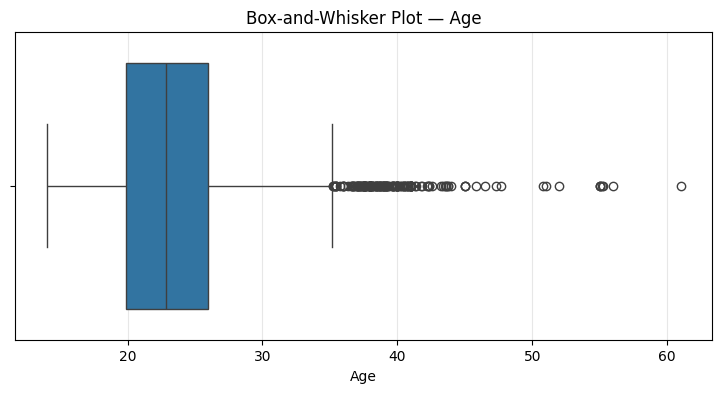

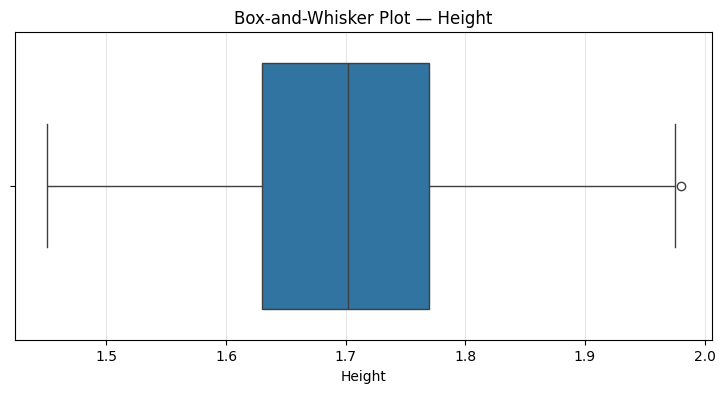

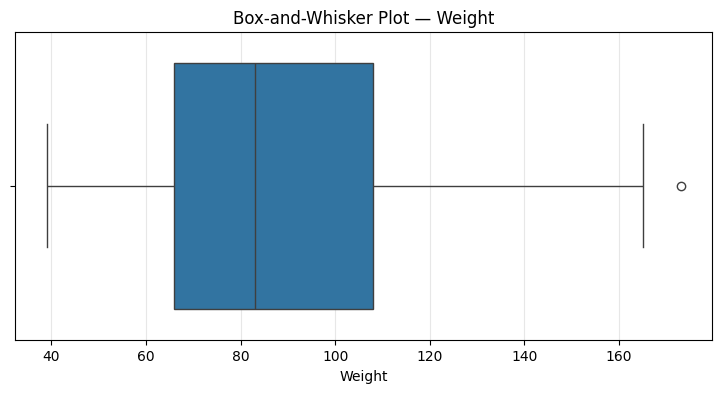

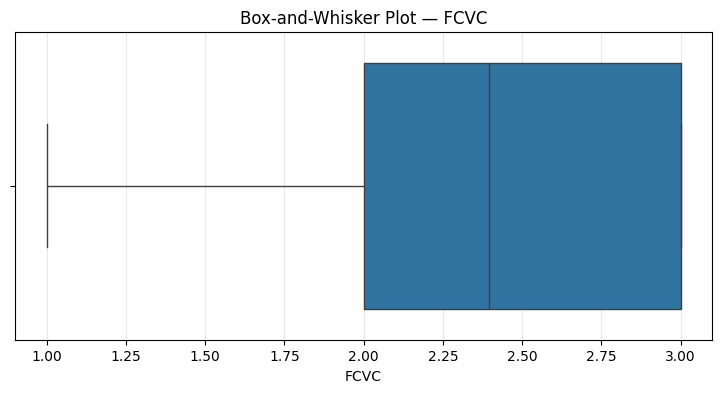

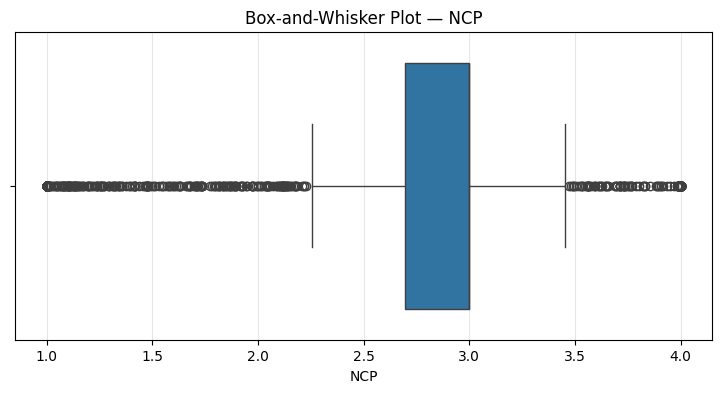

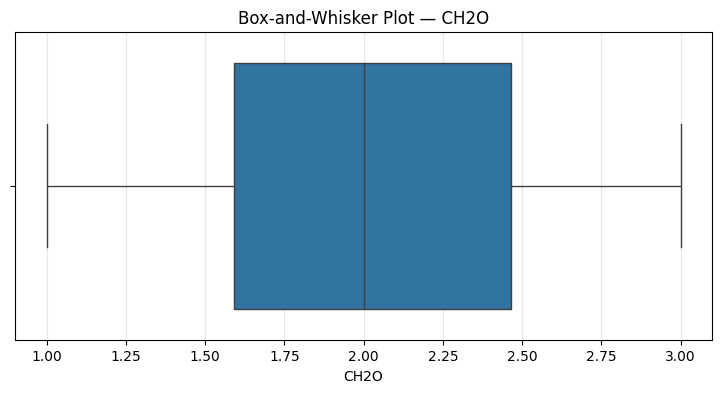

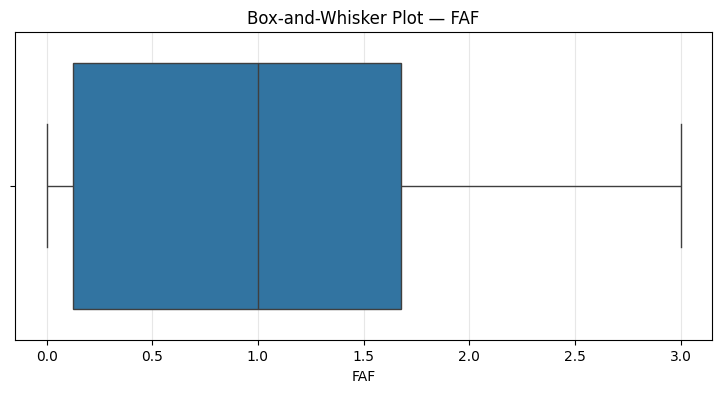

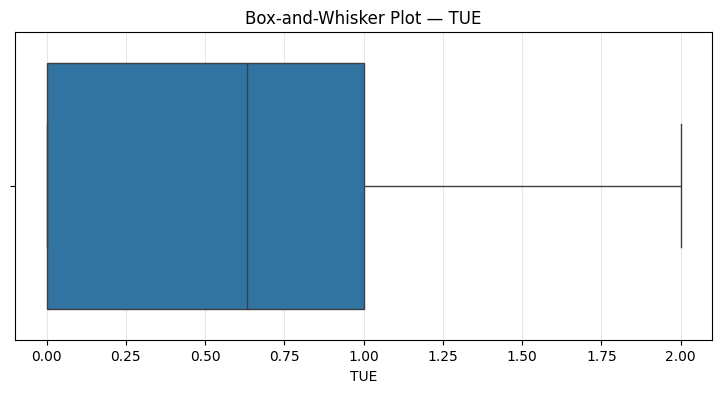

In [ ]:
for column in numeric_columns:

    plt.figure(figsize=(9, 4))

    sns.boxplot(
        data=df,
        x=column
    )

    plt.title(
        f"Box-and-Whisker Plot — {column}"
    )

    plt.xlabel(column)
    plt.grid(
        True,
        axis="x",
        alpha=0.3
    )

    plt.show()

,Age,Height,Weight,FCVC,NCP,CH2O,FAF,TUE
Age,1.0000,-0.0317,0.1982,0.0136,-0.0558,-0.0441,-0.1482,-0.3029
Height,-0.0317,1.0000,0.4575,-0.0404,0.2278,0.2205,0.2936,0.0418
Weight,0.1982,0.4575,1.0000,0.2166,0.0921,0.2038,-0.0565,-0.0794
FCVC,0.0136,-0.0404,0.2166,1.0000,0.0349,0.0813,0.0220,-0.1041
NCP,-0.0558,0.2278,0.0921,0.0349,1.0000,0.0753,0.1278,0.0157
CH2O,-0.0441,0.2205,0.2038,0.0813,0.0753,1.0000,0.1653,0.0207
FAF,-0.1482,0.2936,-0.0565,0.0220,0.1278,0.1653,1.0000,0.0587
TUE,-0.3029,0.0418,-0.0794,-0.1041,0.0157,0.0207,0.0587,1.0000


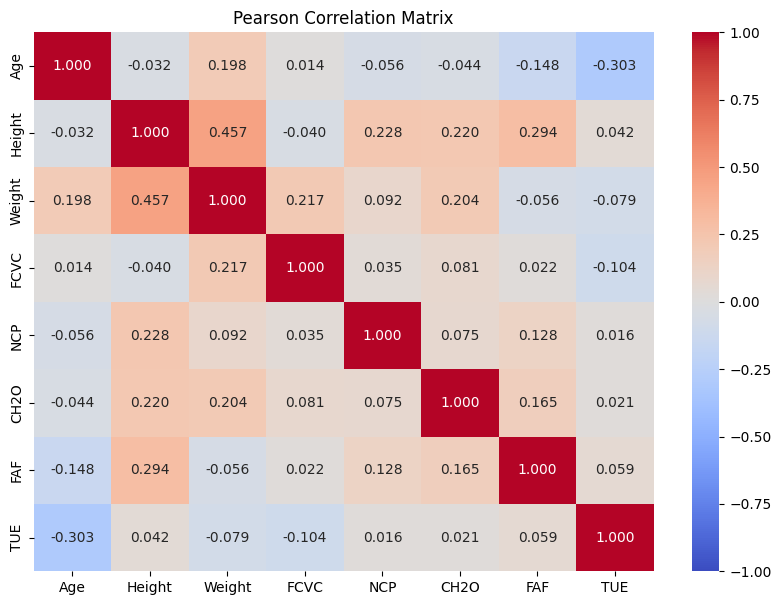

In [ ]:
# Correlation matrix
correlation_matrix = df[numeric_columns].corr(method="pearson")

display(correlation_matrix.round(4))

# Correlation heatmap

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".3f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Pearson Correlation Matrix")
plt.show()